# Predicting Customer Churn: Four Models on Equal Terms

*An AI-assisted revision of three pieces of my M.S. Data Analytics coursework (WGU), produced with Claude (Anthropic). The originals, as submitted, are [D208 Task 2: logistic regression](../../D208-predictive-modeling/), [D209 Task 1: k-nearest neighbors](../../D209-data-mining-1/) and [D209 Task 2: random forest](../../D209-data-mining-1/). The section [Revisiting the originals](#Revisiting-the-originals) lists what changed and why.*

**Question:** which customers of a telecom provider are likely to churn, and how well can that be predicted?

## Summary

- **All four models were put on equal terms:** the same 10,000 customers, the same 36 predictors, the same train/test split and the same scoring, with settings chosen by cross-validation and the test set used once.
- **Logistic regression was the most accurate** (test AUC 0.962, accuracy 90.5%), slightly ahead of gradient boosting (0.957) and the random forest (0.954), with KNN further back (0.935). All are far above the baselines: predicting "no churn" for everyone is 73.5% accurate, and tenure alone gives an AUC of 0.813.
- **Tenure was the missing piece in the original logistic regression.** It had been dropped after a collinearity check. With it, the cross-validated AUC rises from 0.825 to 0.959 and the pseudo R² from 0.24 to 0.62.
- **Churn is concentrated among newer customers on month-to-month contracts.** Each extra month of tenure lowers the churn probability by about 0.8 percentage points on average, and a one- or two-year contract lowers it by about 23 points.
- **The model is useful for targeting.** Contacting the 20% of customers it rates as highest risk reaches 69% of those who churn. Contacting 30% reaches 87%.
- **The data is fictional.** The scores are likely higher than real data would give, and a simple model coming out best may reflect how the data was generated.

## 1. Background

The three originals were separate course exercises. Each course focused on one method, used the same WGU dataset, and followed a rubric that fixed which steps to perform and in what order. They were never meant to be compared with one another, and each used its own variables and its own way of scoring the model.

This revision asks what the same work looks like as a single analysis: every model gets the same customers, the same variables, the same train/test split and the same scoring, and each is compared with a simple baseline. Logistic regression, k-nearest neighbors (KNN) and a random forest are the models the coursework set. **Gradient boosting is an addition** made for this revision, as a widely used modern comparison.

The data is fictional and was provided by WGU, so it isn't included in this repository (see [`data/README.md`](../../data/README.md)). All results below are shown as run.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.precision", 3)
SEED = 31337  # the seed used in the original notebooks

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"Logistic regression": "#2a78d6", "KNN": "#eb6834", "Random forest": "#1baf7a",
          "Gradient boosting": "#eda100", "Baseline": "#9a9993"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

## 2. Data

10,000 customers, one row each, with demographics, the services they subscribe to, account details, eight survey responses and whether they churned in the last month.

In [2]:
raw = pd.read_csv("../../data/churn_clean.csv", index_col=0, keep_default_na=False, na_values=["NA"])
# keep_default_na=False: "None" is a real InternetService category, not a missing value

y = (raw["Churn"] == "Yes").astype(int)
print(f"{len(raw):,} customers, {raw.shape[1]} columns, {int(raw.isna().sum().sum())} missing values")
print(f"Churn rate: {y.mean():.1%}")

10,000 customers, 49 columns, 0 missing values
Churn rate: 26.5%


### Which customers to keep

The originals removed 1,001 customers (10%) as outliers, using the 1.5 × IQR rule on four variables. That step demonstrated the cleaning code from an earlier course and was more aggressive than the data needed. Looking again:

In [3]:
check = ["Population", "Income", "Outage_sec_perweek", "Age", "Tenure", "MonthlyCharge", "Children"]
profile = raw[check].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
q1, q3 = raw[check].quantile(0.25), raw[check].quantile(0.75)
profile["flagged by 1.5 × IQR"] = ((raw[check] < q1 - 1.5 * (q3 - q1)) | (raw[check] > q3 + 1.5 * (q3 - q1))).sum()
profile["skew"] = raw[check].skew()
profile.round(2)

,min,median,max,flagged by 1.5 × IQR,skew
Population,0.00,2910.50,111850.00,937,2.21
Income,348.67,33170.60,258900.70,336,1.46
Outage_sec_perweek,0.10,10.02,21.21,76,0.01
Age,18.00,53.00,89.00,0,0.02
Tenure,1.00,35.43,72.00,0,0.07
MonthlyCharge,79.98,167.48,290.16,0,0.39
Children,0.00,1.00,10.00,401,1.44


Nothing here is impossible or looks like an error. The values the IQR rule flags are large towns, high incomes and big households, which are real customers a model in use would have to score. **All 10,000 customers are kept.** Population and income are strongly right-skewed, so they are log-transformed for the two models that are sensitive to scale (logistic regression and KNN). One oddity is left as it is: 97 customers have a recorded town population of zero.

### Which variables to use

- **Dropped: identifiers and free-text location fields** (customer IDs, city, county, ZIP code, coordinates, time zone, job title). They either identify a single customer or have too many categories to be useful here.
- **Dropped: `Bandwidth_GB_Year`.** It correlates at 0.99 with tenure, so it carries almost no separate information.
- **Kept: everything else,** including tenure. The original logistic regression left tenure out after a collinearity check (section 6 looks at that check again). Monthly charge is also kept for the predictive models, although it turns out to add very little, because it is almost fully determined by the services a customer has.

In [4]:
DROP = ["Churn", "Customer_id", "Interaction", "UID", "City", "State", "County", "Zip", "Lat", "Lng",
        "TimeZone", "Job", "Bandwidth_GB_Year"]
X = raw.drop(columns=DROP)
print(f"Tenure vs. Bandwidth_GB_Year correlation: {raw['Tenure'].corr(raw['Bandwidth_GB_Year']):.3f}")

SKEWED = ["Population", "Income"]
CATEGORICAL = X.select_dtypes("object").columns.tolist()
NUMERIC = [c for c in X.columns if c not in CATEGORICAL + SKEWED]
print(f"{X.shape[1]} predictors: {len(NUMERIC) + len(SKEWED)} numeric, {len(CATEGORICAL)} categorical")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print(f"Training set: {len(X_train):,} customers. Test set: {len(X_test):,} customers, held back until section 5.")

Tenure vs. Bandwidth_GB_Year correlation: 0.991
36 predictors: 18 numeric, 18 categorical
Training set: 7,000 customers. Test set: 3,000 customers, held back until section 5.


The split is the same as in the originals: 70% for training and 30% for testing, stratified so both parts have the same churn rate. Everything that learns from data, including scaling and tuning, uses the training set only.

## 3. Models and how they are tuned

Each model is a pipeline: the preprocessing steps and the model are fitted together, so nothing is learned from data the model is later scored on.

| Model | Preprocessing | Settings tuned |
|---|---|---|
| **Baseline: no model** | none | Predicts "no churn" for everyone. |
| **Baseline: tenure only** | scaling | A logistic regression on tenure alone, the single strongest predictor. |
| **Logistic regression** | log of skewed variables, scaling, one-hot encoding | Regularization strength |
| **KNN** | the same | Number of neighbors, k |
| **Random forest** | one-hot encoding | Minimum leaf size, variables tried per split |
| **Gradient boosting** *(added)* | one-hot encoding | Learning rate, tree size |

**Tuning uses 5-fold cross-validation on the training set.** The training data is split into five parts; each candidate setting is fitted on four parts and scored on the fifth, rotating through all five, and the setting with the best average score is kept. The original KNN notebook chose k by its accuracy on the test set, which makes the test score optimistic. Here the test set plays no part in tuning.

**Settings are scored by AUC,** the probability that the model ranks a randomly chosen churner above a randomly chosen non-churner. With 73.5% of customers not churning, accuracy alone says little.

In [5]:
log_scale = make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())
onehot = OneHotEncoder(drop="if_binary", handle_unknown="ignore")

scaled = ColumnTransformer([("skewed", log_scale, SKEWED), ("numeric", StandardScaler(), NUMERIC),
                            ("categorical", onehot, CATEGORICAL)])
unscaled = ColumnTransformer([("numeric", "passthrough", SKEWED + NUMERIC), ("categorical", onehot, CATEGORICAL)])

CANDIDATES = {
    "Logistic regression": (
        Pipeline([("prep", scaled), ("model", LogisticRegression(max_iter=5000))]),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "KNN": (
        Pipeline([("prep", scaled), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [5, 15, 25, 51, 101, 201, 301, 401, 601]}),
    "Random forest": (
        Pipeline([("prep", unscaled), ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
        {"model__min_samples_leaf": [1, 5, 20, 50], "model__max_features": ["sqrt", 0.33, 0.5]}),
    "Gradient boosting": (
        Pipeline([("prep", unscaled), ("model", HistGradientBoostingClassifier(random_state=SEED))]),
        {"model__learning_rate": [0.03, 0.1], "model__max_leaf_nodes": [7, 15, 31], "model__max_iter": [100, 300]}),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
searches = {}
for name, (pipeline, grid) in CANDIDATES.items():
    searches[name] = GridSearchCV(pipeline, grid, cv=folds, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

cv_table = pd.DataFrame({
    name: {"cross-validated AUC": s.best_score_,
           "± across folds": s.cv_results_["std_test_score"][s.best_index_],
           "settings chosen": ", ".join(f"{k.split('__')[1]}={v}" for k, v in s.best_params_.items())}
    for name, s in searches.items()}).T
cv_table

,cross-validated AUC,± across folds,settings chosen
Logistic regression,0.959,0.005,C=1
KNN,0.932,0.004,n_neighbors=401
Random forest,0.952,0.005,"max_features=0.33, min_samples_leaf=20"
Gradient boosting,0.956,0.005,"learning_rate=0.03, max_iter=300, max_leaf_nod..."


Random forest, cross-validated AUC: 0.9499 with default settings, 0.9515 tuned


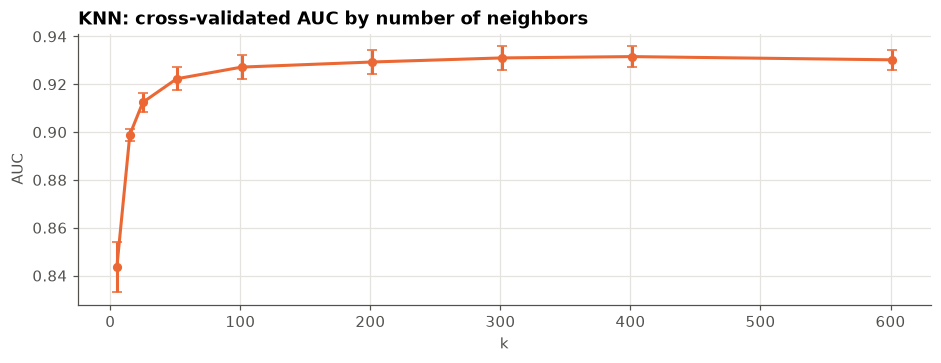

In [6]:
# How much did tuning matter for the random forest, and how does KNN respond to k?
default_forest = Pipeline([("prep", unscaled), ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))])
default_auc = cross_val_score(default_forest, X_train, y_train, cv=folds, scoring="roc_auc").mean()
print(f"Random forest, cross-validated AUC: {default_auc:.4f} with default settings, "
      f"{searches['Random forest'].best_score_:.4f} tuned")

knn_cv = pd.DataFrame(searches["KNN"].cv_results_)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.errorbar(knn_cv["param_model__n_neighbors"].astype(int), knn_cv["mean_test_score"], yerr=knn_cv["std_test_score"],
            color=COLORS["KNN"], marker="o", ms=5, capsize=3)
ax.set(title="KNN: cross-validated AUC by number of neighbors", xlabel="k", ylabel="AUC")
plt.show()

- **Three of the four models are close in cross-validation:** logistic regression 0.959, gradient boosting 0.956 and the random forest 0.952, with KNN at 0.932. The variation between folds is about ±0.005, so the first three are within noise of each other at this stage.
- **KNN does best with a very large k.** Its score keeps improving up to about 400 neighbors and is nearly flat from 200 to 600. With 36 predictors, most of which carry little signal, distances between customers are noisy, and averaging over many neighbors compensates. The original used two predictors, where a smaller k (86) was reasonable.
- **Tuning made little difference to the random forest:** 0.9515 tuned, against 0.9499 with default settings.
- Logistic regression settled on the default regularization strength (C = 1).

## 4. Baselines

Two reference points, scored on the test set alongside the models in the next section.

In [7]:
baselines = {
    "Baseline: no model": DummyClassifier(strategy="prior").fit(X_train, y_train),
    "Baseline: tenure only": make_pipeline(
        ColumnTransformer([("tenure", StandardScaler(), ["Tenure"])]), LogisticRegression()).fit(X_train, y_train),
}
fitted = {**baselines, **{name: s.best_estimator_ for name, s in searches.items()}}
proba = {name: model.predict_proba(X_test)[:, 1] for name, model in fitted.items()}
print(f"Share of test customers who did not churn: {1 - y_test.mean():.1%}")

Share of test customers who did not churn: 73.5%


## 5. Results on the test set

The test set is used here for the first time. Each model was refitted on the full training set with its chosen settings.

- **Accuracy, precision and recall** use the default cutoff of 50%: a customer is predicted to churn if the model puts the probability above one half. Precision is the share of predicted churners who did churn. Recall is the share of actual churners the model caught.
- **AUC** and **PR-AUC** (the area under the precision–recall curve) measure how well the model ranks customers, across all cutoffs.
- **Brier score** is the mean squared error of the predicted probabilities, so lower is better. The original random forest notebook reported MSE on its yes/no predictions; this is the form of that measure that suits a classifier.

In [8]:
def scores(p):
    pred = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_test, pred), "AUC": roc_auc_score(y_test, p),
            "PR-AUC": average_precision_score(y_test, p), "Brier": brier_score_loss(y_test, p),
            "Precision": precision_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred)}


results = pd.DataFrame({name: scores(p) for name, p in proba.items()}).T

# 95% bootstrap intervals for AUC: resample the test customers 1,000 times
rng = np.random.default_rng(SEED)
y_arr = y_test.to_numpy()
draws = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(1000)]
boot = {name: np.array([roc_auc_score(y_arr[i], p[i]) for i in draws]) for name, p in proba.items() if "no model" not in name}
results["AUC 95% interval"] = pd.Series({name: f"{np.percentile(b, 2.5):.3f}–{np.percentile(b, 97.5):.3f}" for name, b in boot.items()})
results.fillna({"AUC 95% interval": ""})

,Accuracy,AUC,PR-AUC,Brier,Precision,Recall,AUC 95% interval
Baseline: no model,0.735,0.500,0.265,0.195,0.000,0.000,
Baseline: tenure only,0.751,0.813,0.550,0.146,0.538,0.430,0.797–0.829
Logistic regression,0.905,0.962,0.907,0.068,0.819,0.823,0.955–0.967
KNN,0.787,0.935,0.839,0.132,0.976,0.203,0.926–0.944
Random forest,0.894,0.954,0.887,0.076,0.816,0.776,0.947–0.960
Gradient boosting,0.901,0.957,0.895,0.072,0.823,0.796,0.950–0.963


In [9]:
MODELS = list(searches)
BEST = cv_table["cross-validated AUC"].astype(float).idxmax()  # chosen by cross-validation, not by test score

gaps = pd.DataFrame({other: {"AUC gap": (boot[BEST] - boot[other]).mean(),
                              "95% interval": f"{np.percentile(boot[BEST] - boot[other], 2.5):+.3f} to {np.percentile(boot[BEST] - boot[other], 97.5):+.3f}"}
                     for other in MODELS if other != BEST}).T
print(f"Best model in cross-validation: {BEST}. Its test AUC minus each other model's:")
gaps

Best model in cross-validation: Logistic regression. Its test AUC minus each other model's:


,AUC gap,95% interval
KNN,0.026,+0.021 to +0.032
Random forest,0.008,+0.005 to +0.011
Gradient boosting,0.005,+0.003 to +0.007


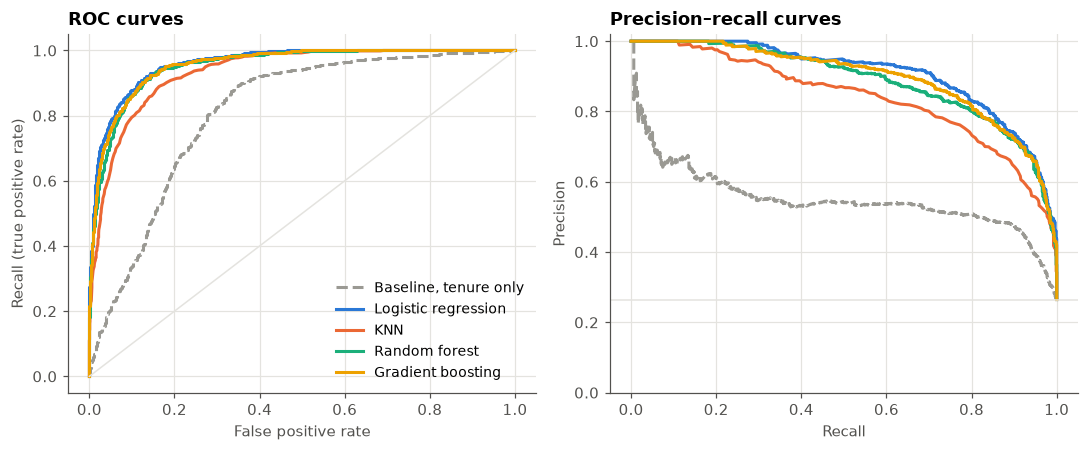

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for name in ["Baseline: tenure only"] + MODELS:
    color = COLORS.get(name, COLORS["Baseline"])
    style = "--" if name.startswith("Baseline") else "-"
    fpr, tpr, _ = roc_curve(y_test, proba[name])
    axes[0].plot(fpr, tpr, color=color, ls=style, label=name.replace("Baseline: ", "Baseline, "))
    prec, rec, _ = precision_recall_curve(y_test, proba[name])
    axes[1].plot(rec, prec, color=color, ls=style)
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1)
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="Recall (true positive rate)")
axes[1].axhline(y_test.mean(), color=GRID, lw=1)
axes[1].set(title="Precision–recall curves", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
axes[0].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

- **Every model clears both baselines by a wide margin.** Predicting "no churn" for everyone is 73.5% accurate and catches no churners. Tenure alone reaches an AUC of 0.813.
- **Logistic regression has the best score on every measure except precision:** AUC 0.962, PR-AUC 0.907, accuracy 90.5% and the lowest Brier score. At the 50% cutoff it catches 82% of churners, and 82% of the customers it flags do churn.
- **Gradient boosting and the random forest are close behind** (AUC 0.957 and 0.954). The gaps to logistic regression are small, 0.005 and 0.008, but the bootstrap intervals for those gaps exclude zero, so on this test set they are unlikely to be chance.
- **KNN ranks customers reasonably well (AUC 0.935) but does poorly at the 50% cutoff** (78.7% accuracy, 20% recall). Averaging over 401 neighbors pulls its probabilities toward the overall churn rate, so few customers pass 50%. The calibration chart below shows this directly.
- **A simple model coming out best is itself a finding.** The more flexible models could have picked up interactions and non-linear effects, and gained nothing from them. That is probably a feature of this fictional dataset, whose churn pattern appears close to a logistic relationship, and shouldn't be expected on real data.

### Are the predicted probabilities trustworthy?

Section 7 uses the predicted probabilities to decide whom to contact, so they need to mean what they say: of the customers given a 30% chance of churning, about 30% should churn. The chart groups test customers by predicted probability and compares each group's average prediction with its actual churn rate. A well-calibrated model follows the diagonal.

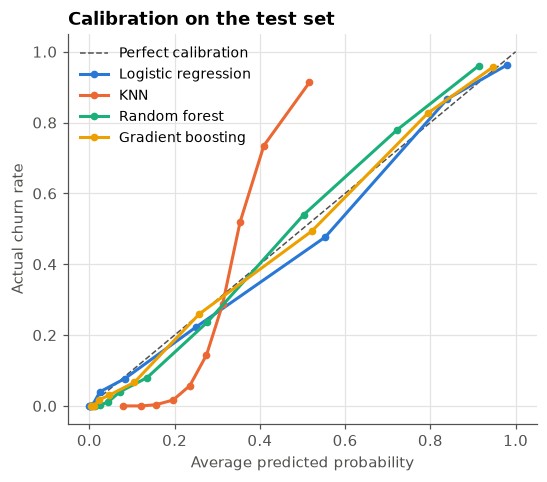

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.plot([0, 1], [0, 1], color=INK_2, lw=1, ls="--", label="Perfect calibration")
for name in MODELS:
    observed, predicted = calibration_curve(y_test, proba[name], n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, color=COLORS[name], marker="o", ms=4, label=name)
ax.set(title="Calibration on the test set", xlabel="Average predicted probability", ylabel="Actual churn rate")
ax.legend(loc="upper left", fontsize=9)
plt.show()

Logistic regression, gradient boosting and the random forest all stay close to the diagonal, so their probabilities can be taken at face value. KNN does not: its predictions are squeezed into a narrow band, and the customers it scores at about 40% churn roughly three-quarters of the time. KNN's probabilities would need recalibrating before they could be used with a fixed cutoff.

## 6. What drives churn?

The original logistic regression asked which factors contribute to churn. This section answers that with tenure included.

### The collinearity check, recomputed

The original dropped five variables because their variance inflation factors (VIF) were high: tenure, bandwidth, outage time, phone service and DSL. VIF measures how well each variable can be predicted from the others, and a common rule of thumb treats values above 5 or 10 as a problem. The `statsmodels` function expects the data to include a constant column. Without one, a variable whose average is far from zero can look collinear when it isn't. The table recomputes VIF four ways, on this notebook's training data and variables.

In [12]:
design = pd.get_dummies(X_train.assign(Bandwidth_GB_Year=raw.loc[X_train.index, "Bandwidth_GB_Year"]),
                        drop_first=True, dtype=float)


def vif(frame, constant):
    m = sm.add_constant(frame) if constant else frame
    return pd.Series([variance_inflation_factor(m.values, i) for i in range(m.shape[1])], index=m.columns).drop("const", errors="ignore")


flagged = ["Tenure", "Bandwidth_GB_Year", "Outage_sec_perweek", "Phone_Yes", "MonthlyCharge", "StreamingMovies_Yes"]
vif_table = pd.DataFrame({
    "No constant (as in the original)": vif(design, constant=False),
    "With a constant": vif(design, constant=True),
    "Bandwidth dropped": vif(design.drop(columns="Bandwidth_GB_Year"), constant=True),
    "Bandwidth and monthly charge dropped": vif(design.drop(columns=["Bandwidth_GB_Year", "MonthlyCharge"]), constant=True),
})
print(f"Highest VIF with bandwidth and monthly charge dropped: {vif_table.iloc[:, 3].max():.1f}")
services = pd.get_dummies(X_train.drop(columns="MonthlyCharge"), drop_first=True, dtype=float)
r2 = sm.OLS(X_train["MonthlyCharge"], sm.add_constant(services)).fit().rsquared
print(f"Share of the variation in monthly charge explained by the other variables: {r2:.1%}")
vif_table.loc[flagged].round(1)

Highest VIF with bandwidth and monthly charge dropped: 2.2
Share of the variation in monthly charge explained by the other variables: 95.8%


,No constant (as in the original),With a constant,Bandwidth dropped,Bandwidth and monthly charge dropped
Tenure,25852.0,61169.8,1.0,1.0
Bandwidth_GB_Year,33074.5,62395.1,NaN,NaN
Outage_sec_perweek,12.2,1.0,1.0,1.0
Phone_Yes,10.6,1.0,1.0,1.0
MonthlyCharge,1443.2,218.7,23.6,NaN
StreamingMovies_Yes,13.2,21.4,9.9,1.0


- **Tenure and bandwidth are collinear with each other, with or without a constant.** They correlate at 0.99. Dropping bandwidth alone brings tenure's VIF down to 1.0, so tenure didn't need to be removed.
- **Outage time and phone service were false alarms.** Their VIFs are above 10 without a constant and 1.0 with one.
- **Monthly charge is a separate case.** Even with bandwidth gone its VIF is 23.6, because 95.8% of its variation is explained by the other variables: the charge is close to a sum of the services a customer has. With both dropped, no VIF is above 2.2.

How much do tenure and monthly charge each contribute to prediction?

In [13]:
def cv_auc(columns):
    prep = ColumnTransformer([("skewed", log_scale, [c for c in columns if c in SKEWED]),
                              ("numeric", StandardScaler(), [c for c in columns if c in NUMERIC]),
                              ("categorical", onehot, [c for c in columns if c in CATEGORICAL])])
    model = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=5000))])
    return cross_val_score(model, X_train[columns], y_train, cv=folds, scoring="roc_auc").mean()


every = list(X_train.columns)
pd.Series({
    "All predictors": cv_auc(every),
    "Without monthly charge": cv_auc([c for c in every if c != "MonthlyCharge"]),
    "Without tenure": cv_auc([c for c in every if c != "Tenure"]),
    "Without tenure or monthly charge": cv_auc([c for c in every if c not in ("Tenure", "MonthlyCharge")]),
}, name="Logistic regression, cross-validated AUC").to_frame().round(4)

,"Logistic regression, cross-validated AUC"
All predictors,0.959
Without monthly charge,0.958
Without tenure,0.825
Without tenure or monthly charge,0.823


Tenure is what matters. Removing it costs 0.134 of AUC; removing monthly charge costs about 0.002. The original model's weak fit came from leaving out tenure.

For prediction, keeping monthly charge does no harm, so it stays in the models above. For reading effects it gets in the way: with monthly charge in the model, each service's effect would mean "the effect of having this service at the same monthly charge", which isn't a meaningful comparison. So the effects below come from a model without it.

### Effects on churn

A logistic regression fitted on the training data, with the same variables as the models above except monthly charge, which is left out here for the reason just given. Two ways of reading each effect are shown:

- **Odds ratio:** how the *odds* of churning (the probability of churning divided by the probability of not churning) are multiplied. An odds ratio of 2 doubles the odds; it doesn't double the probability. The original write-up read odds ratios as changes in likelihood, which overstates them.
- **Average change in churn probability:** the average effect on the predicted probability itself, in percentage points. This is the easier figure to act on.

For yes/no variables the effect is for "yes" compared with "no". For contract and internet service it is compared with a month-to-month contract and with DSL. For tenure it is per additional month.

In [14]:
inference = pd.get_dummies(X_train.drop(columns="MonthlyCharge"), drop_first=True, dtype=float)
inference[SKEWED] = np.log1p(inference[SKEWED])
logit = sm.Logit(y_train, sm.add_constant(inference)).fit(disp=False)
margins = logit.get_margeff().summary_frame()

effects = pd.DataFrame({
    "Odds ratio": np.exp(logit.params),
    "95% low": np.exp(logit.conf_int()[0]),
    "95% high": np.exp(logit.conf_int()[1]),
    "Avg. change in churn probability, pts": margins["dy/dx"] * 100,
    "p-value": logit.pvalues,
}).drop("const")
print(f"Pseudo R²: {logit.prsquared:.3f}   (the original model, without tenure: 0.241)")
print(f"{(effects['p-value'] < 0.05).sum()} of {len(effects)} variables are significant at the 5% level. Tenure, and the others with the largest effects:")
significant = effects[effects["p-value"] < 0.05]
largest = significant.drop("Tenure").reindex(significant.drop("Tenure")["Avg. change in churn probability, pts"].abs().sort_values(ascending=False).index).head(11)
pd.concat([effects.loc[["Tenure"]], largest]).round(3)

Pseudo R²: 0.616   (the original model, without tenure: 0.241)
16 of 44 variables are significant at the 5% level. Tenure, and the others with the largest effects:


,Odds ratio,95% low,95% high,"Avg. change in churn probability, pts",p-value
Tenure,0.894,0.888,0.900,-0.770,0.000
StreamingMovies_Yes,32.220,25.283,41.061,23.898,0.000
Contract_One year,0.034,0.025,0.045,-23.344,0.000
Contract_Two Year,0.035,0.026,0.046,-23.146,0.000
StreamingTV_Yes,21.020,16.697,26.461,20.958,0.000
Multiple_Yes,5.698,4.674,6.947,11.975,0.000
InternetService_None,0.223,0.171,0.289,-10.341,0.000
InternetService_Fiber Optic,0.238,0.192,0.295,-9.883,0.000
Techie_Yes,3.036,2.386,3.864,7.643,0.000
OnlineBackup_Yes,2.365,1.965,2.847,5.925,0.000


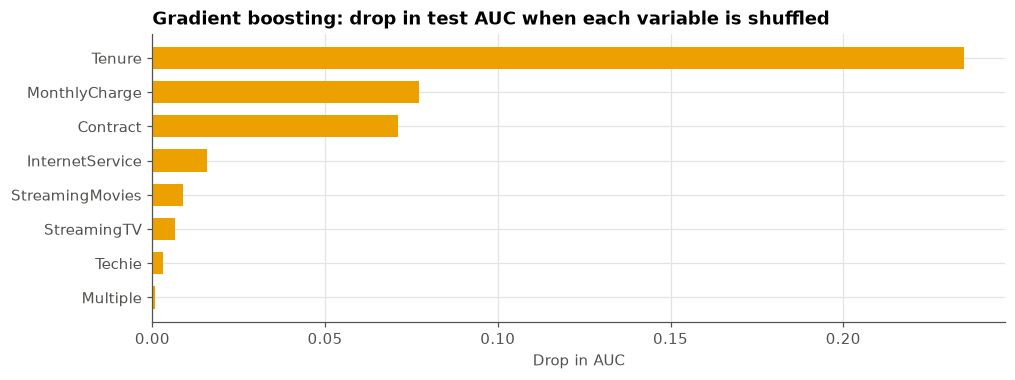

In [15]:
# A cross-check that doesn't depend on the logistic model: permutation importance for gradient boosting.
# Each variable is shuffled in turn, and the drop in test AUC shows how much the model relied on it.
perm = permutation_importance(fitted["Gradient boosting"], X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(8)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(importance.index, importance.values, color=COLORS["Gradient boosting"], height=0.65)
ax.set(title="Gradient boosting: drop in test AUC when each variable is shuffled", xlabel="Drop in AUC")
plt.show()

- **Tenure is the strongest single predictor.** Each additional month lowers the churn probability by about 0.8 percentage points on average, which adds up to a large difference between a new customer and one of several years' standing. It is also by far the variable gradient boosting relies on most.
- **Contract type comes next.** Compared with month-to-month customers, those on one- or two-year contracts are about 23 points less likely to churn.
- **Customers with streaming services and multiple lines churn more,** at the same tenure and contract: by about 24 points for streaming movies, 21 for streaming TV and 12 for multiple lines. The odds ratios for the streaming services are above 20. That is more extreme than real data would be likely to show, and is probably a feature of how this dataset was generated.
- **DSL customers churn more than fiber-optic customers or those without internet service,** by about 10 points.
- **The two views agree.** Gradient boosting leans on tenure, monthly charge and contract. Monthly charge there stands in for the services, which it summarizes.
- **Most variables matter little.** Only 16 of 44 are significant at the 5% level. Demographics, location and the eight survey responses contribute very little.

## 7. From predictions to a decision: whom to contact

A churn model is useful when it changes what the business does, for example by choosing which customers get a retention offer. That choice depends on two costs: the cost of an offer to a customer who would have stayed anyway, and the cost of missing a customer who then leaves.

**This data is fictional, and nothing in it supports an estimate of either cost.** So this section doesn't invent dollar figures. It shows how the decision changes with the *ratio* between the two costs. If missing a churner costs *r* times as much as an unnecessary offer, the cost-minimizing rule for a well-calibrated model is to contact every customer whose predicted churn probability is above 1 / (1 + *r*).

The model used is the one that did best in cross-validation.

In [16]:
p_best = proba[BEST]
rows = []
for ratio in [1, 2, 5, 10]:
    cutoff = 1 / (1 + ratio)
    contact = p_best >= cutoff
    missed = int(((~contact) & (y_arr == 1)).sum())
    wasted = int((contact & (y_arr == 0)).sum())
    cost = wasted + ratio * missed
    rows.append({
        "Missed churner costs (× an unneeded offer)": ratio,
        "Contact if probability ≥": f"{cutoff:.0%}",
        "Customers contacted": f"{contact.mean():.0%}",
        "Churners reached (recall)": f"{recall_score(y_arr, contact):.0%}",
        "Contacted who would churn (precision)": f"{precision_score(y_arr, contact):.0%}",
        "Cost vs. contacting no one": f"{cost / (ratio * y_arr.sum()):.0%}",
        "Cost vs. contacting everyone": f"{cost / (y_arr == 0).sum():.0%}",
    })
print(f"Model: {BEST}. Test set: {len(y_arr):,} customers, {int(y_arr.sum()):,} churners.")
decision = pd.DataFrame(rows).set_index("Missed churner costs (× an unneeded offer)")
decision.T

Model: Logistic regression. Test set: 3,000 customers, 795 churners.


Missed churner costs (× an unneeded offer),1,2,5,10
Contact if probability ≥,50%,33%,17%,9%
Customers contacted,27%,31%,39%,44%
Churners reached (recall),82%,88%,95%,97%
Contacted who would churn (precision),82%,75%,65%,59%
Cost vs. contacting no one,36%,27%,15%,10%
Cost vs. contacting everyone,13%,19%,27%,36%


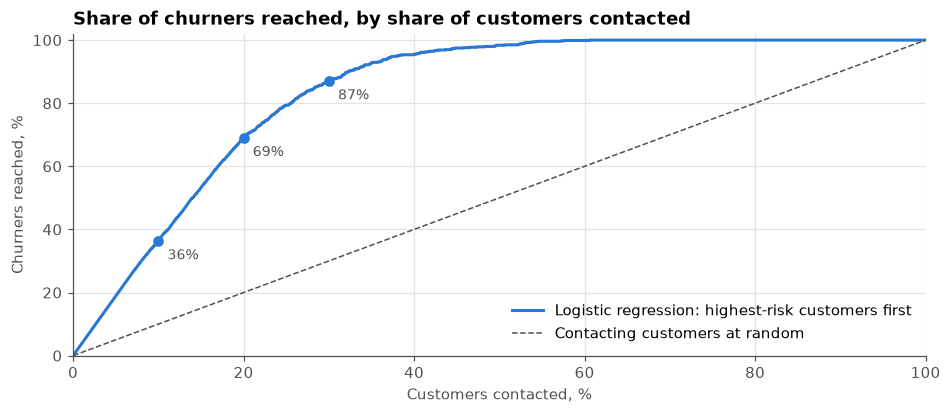

In [17]:
order = np.argsort(-p_best)
share_contacted = np.arange(1, len(order) + 1) / len(order)
share_reached = np.cumsum(y_arr[order]) / y_arr.sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(share_contacted * 100, share_reached * 100, color=COLORS[BEST], label=f"{BEST}: highest-risk customers first")
ax.plot([0, 100], [0, 100], color=INK_2, lw=1, ls="--", label="Contacting customers at random")
for pct in (10, 20, 30):
    reached = share_reached[int(len(order) * pct / 100) - 1] * 100
    ax.annotate(f"{reached:.0f}%", (pct, reached), xytext=(6, -12), textcoords="offset points", fontsize=9, color=INK_2)
    ax.plot(pct, reached, "o", color=COLORS[BEST], ms=6)
ax.set(title="Share of churners reached, by share of customers contacted", xlabel="Customers contacted, %",
       ylabel="Churners reached, %", xlim=(0, 100), ylim=(0, 102))
ax.legend(loc="lower right")
plt.show()

- **The model concentrates churners at the top of the list.** Contacting the 10% of customers with the highest predicted risk reaches 36% of all churners. Contacting 20% reaches 69%, and 30% reaches 87%. Contacting customers at random would reach 10%, 20% and 30%.
- **The right cutoff depends on the cost ratio.** If a missed churner costs the same as an unneeded offer, the rule is to contact customers above 50%: that is 27% of customers, and it reaches 82% of churners. If a missed churner costs ten times as much, the cutoff falls to 9%: 44% of customers are contacted and 97% of churners are reached.
- **Across that range, using the model costs much less than either blanket policy:** between 10% and 36% of the cost of contacting no one, and between 13% and 36% of the cost of contacting everyone.
- **What the business would need to supply** is the cost of an offer, the value of a retained customer, and how often an offer changes a customer's mind. The last one matters most and isn't in this data. This analysis treats every contacted churner as one the business had a chance to keep, which a real campaign would have to test.

## 8. What the evidence supports

- **On equal terms, logistic regression was the best of the four models,** with gradient boosting and the random forest close behind and KNN clearly weaker. The original coursework gave the opposite impression mainly because its logistic regression lacked tenure.
- **Getting the inputs right mattered more than the choice of algorithm.** Adding one variable moved logistic regression's AUC from about 0.83 to 0.96. Switching between the three best algorithms moved it by less than 0.01.
- **The model supports a concrete decision.** It ranks customers well enough that a retention campaign aimed at the top fifth would reach about seven in ten churners, and its probabilities are calibrated well enough to set a cutoff from a cost ratio.
- **These results describe a fictional dataset.** The method carries over to real data. The scores and the ranking of models may not.

## Revisiting the originals

The three originals did what their courses asked: each implemented one method on the churn data and documented it against a rubric. The rubric also fixed the order of the steps, which is why, for example, the full dataset was prepared before it was split. Coming back to them as one analysis, I saw several opportunities to make the work closer to what a real project would need. I went through each one and decided how to handle it:

| In the originals | In this revision | What I took from it |
|---|---|---|
| Three separate notebooks, each with its own variables and scoring | One notebook; every model gets the same customers, variables, split and scoring | The courses each focused on one method. Putting them side by side is what makes the results comparable |
| Logistic regression without tenure | Tenure included; bandwidth dropped as a near-duplicate of it | Tenure and bandwidth were collinear with each other, so only one of the pair had to go. Tenure turned out to be the strongest predictor in the data |
| 1,001 customers removed as outliers | All 10,000 kept; skewed variables log-transformed | The removal demonstrated the cleaning code from an earlier course. For prediction, unusual customers still have to be scored |
| KNN's k chosen by test-set accuracy | Every setting chosen by 5-fold cross-validation on the training set | The test set can only give an honest score if it plays no part in choosing the model |
| No baseline; accuracy as the main measure | Two baselines; AUC, PR-AUC, Brier score, precision and recall | The rubrics didn't call for baselines. In practice a model has to be judged against what you'd do without it |
| Random forest tuned on a narrow grid, then wrapped in AdaBoost; MSE reported on yes/no predictions | Wider grid on the settings that matter; gradient boosting added as its own model; Brier score in place of MSE | Each step in a pipeline should be there for a reason that can be stated |
| Odds ratios read as changes in likelihood | Odds ratios labelled as odds, with average changes in probability alongside | The probability scale is the one a business reader needs |
| Ended at model accuracy | A decision section: whom to contact, across a range of cost assumptions | A model's value is in the decision it supports |

The reasoning behind each decision is recorded in this project's [README](README.md#decision-log).

## Limitations

- **The data is fictional.** Its patterns are cleaner than real customer data would be, so the scores here are likely higher than a real project would reach, and the ranking of models could differ on real data.
- **A single train/test split.** The bootstrap intervals show how much the test scores could vary with a different sample of test customers, but not with a different split.
- **A snapshot, not a timeline.** The data records who churned in one month. A real churn model would be trained on earlier months and tested on later ones.
- **No costs.** The decision section shows how the answer changes with the cost ratio, but only the business could say which ratio applies.
- **Associations, not causes.** The effects in section 6 describe which customers churn more often. They don't show that changing a customer's contract or services would change whether they stay.